In [1]:
import logging
import pandas as pd
import config.config as config
import data.process as processing
import features.pipeline as pipeline
from typing import Dict
from features.utils import shift_quarters
from config.config import constituent_dict
from config.config import quarters_dict

logging.getLogger().setLevel(logging.WARNING)

# Import Strategy Data
df_dict = config.df_dict

# Import Market Data
market_data = config.market_prices

# Process Raw Strategy Data
processed_df_dict = processing.process_data(df_dict)

# Feature Engineer
engineered_data = pipeline.process_data(processed_df_dict)

# Construct Eval data
eval_data = shift_quarters(engineered_data, shift=2)

2025-06-02 09:05:13,639 - config.config - WARNING - No data available for Q3_2007
2025-06-02 09:05:13,887 - config.config - INFO - {'clustering_method': 'KMeans', 'n_clusters': 17, 'seed': 42, 'n_init': 10, 'num_stocks': 10, 'parallel': False, 'threshold': 0.25, 'buy_amount': 100}
2025-06-02 09:05:17,564 - features.pipeline - WARNING - No data generated for cluster 16
2025-06-02 09:05:20,610 - features.pipeline - WARNING - No data generated for cluster 11
2025-06-02 09:05:22,612 - features.pipeline - WARNING - No data generated for cluster 15
2025-06-02 09:05:25,004 - features.pipeline - WARNING - No data generated for cluster 1
2025-06-02 09:05:27,962 - features.pipeline - WARNING - No data generated for cluster 4
2025-06-02 09:05:30,029 - features.pipeline - WARNING - No data generated for cluster 9


In [3]:
import models.pipeline as model_pipeline
from config.config import constituent_dict

strategies = model_pipeline.process_models(engineered_data)
signal = model_pipeline.make_predict(strategies, eval_data)

/Users/parkercarrus/Desktop/Clustering-Paper.nosync/models/utils.py:42: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(0)


In [4]:
import backtest.process as backtest

value = backtest.get_portfolio_value(signal)

In [6]:
# Test

# Ensure this code block prints nothing
count = 0
for quarter in signal.iterrows():
    quarter_consts = constituent_dict[quarter[0]]
    for equity in quarter[1].index:
        if quarter[1][equity] == 1:
            if equity not in quarter_consts:
                count+=1
                print(equity)

if count == 0:
    print("Model successfully purchases according to quarterly constituents")

constituent_list = list(constituent_dict.values())
leavers = set()
rejoiners = set()
for i in range(len(constituent_list)):
    for equity in constituent_list[i]:
        if equity in leavers:
            rejoiners.add(equity)
        for k in range(i+1, len(constituent_list)-1):
            if equity not in constituent_list[k]:
                leavers.add(equity)

print(f"Number of purchased stocks that left universe: {len(leavers)}")

Model successfully purchases according to quarterly constituents
Number of purchased stocks that left universe: 408


In [7]:
from config.config import market_prices

price_matrix = market_prices.copy()
# Convert market_prices index to Datetime

price_matrix['date'] = pd.to_datetime(price_matrix['date'])
price_matrix = price_matrix.drop(columns=['index', 'Unnamed: 0'], errors='ignore')
price_matrix = price_matrix.set_index('date')

missing_cols = sum([col not in signal for col in price_matrix])
print(f"There are {missing_cols} columns present in market_prices but not present in signal")

print("\nRemoving missing columns from price matrix")
cols = []
for col in price_matrix:
    if col not in signal.columns:
        cols.append(col)

price_matrix_cleaned = price_matrix.drop(columns=cols)

assert price_matrix_cleaned.shape[1] == signal.shape[1], "Signal and market matricies not alligned on column axis"
assert all(col in price_matrix_cleaned.columns for col in signal.columns), "Not all signal columns are present in market_prices_cleaned"

There are 147 columns present in market_prices but not present in signal

Removing missing columns from price matrix


In [8]:
# Convert signal_matrix index to Datetime
quarter_dates = [pd.to_datetime(quarters_dict[q]) for q in signal.index]
signal_dated = signal.copy()
signal_dated.index = pd.DatetimeIndex(quarter_dates, name='date')

# Filter price_matrix to start at the same date as signal_dated
price_matrix_cleaned = price_matrix_cleaned.loc[signal_dated.index.min():]

In [9]:
# Print each date between the first and last index in signal_dated
for date in pd.date_range(signal_dated.index.min() + pd.Timedelta(days=1), price_matrix.index.max(), freq='D'):
    if date not in signal_dated.index and date in price_matrix.index:
        # Add a row with all zero values for the columns in signal_dated at this date
        signal_dated.loc[date] = 0
        signal_dated = signal_dated.sort_index()

assert signal_dated.shape == price_matrix_cleaned.shape

In [10]:
def scale_buy_signal(stretched_signal, price_data, purchase_amount):
    mask = stretched_signal == 1
    scaled_signal = stretched_signal.copy().astype(float)
    scaled_signal[mask] = purchase_amount / price_data[mask]

    return scaled_signal

scaled_signal = scale_buy_signal(signal_dated, price_matrix_cleaned, 100)

,PCP,MDT,FIS,HST,R,KEY,CAM,CSRA,DFS,XOM,...,IPGP,MU,SNPS,MCD,POM,VRTX,EQR,EP,GPS,TFC
date,,,,,,,,,,,,,,,,,,,,,
2008-02-15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,14.025245,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-02-19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-02-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-02-21,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008-02-22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-12-26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2024-12-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
signal_cumsum = scaled_signal.cumsum()
ledger = signal_cumsum * price_matrix_cleaned
portfolio_value = ledger.sum(axis=1)

In [16]:
import yfinance as yf

spy = yf.download("SPY", start=signal_dated.index.min().strftime('%Y-%m-%d'), end=signal_dated.index.max().strftime('%Y-%m-%d'))

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


In [17]:
spy_purchases = {}
for date in quarters_dict.values():
    if date in spy.index:
        spy_value = spy.loc[date]['Close'].values
        spy_shares = 100 / spy_value
        spy_purchases[date] = spy_shares

spy_purchase_df = pd.DataFrame(spy_purchases)
spy_purchase_df = spy_purchase_df.T

In [18]:
spy_purchase_df * spy['Close']

,0,SPY
2008-02-15,NaN,NaN
2008-05-15,NaN,NaN
2008-08-15,NaN,NaN
2008-11-17,NaN,NaN
2009-02-17,NaN,NaN
...,...,...
2024-12-23 00:00:00,NaN,NaN
2024-12-24 00:00:00,NaN,NaN
2024-12-26 00:00:00,NaN,NaN
2024-12-27 00:00:00,NaN,NaN


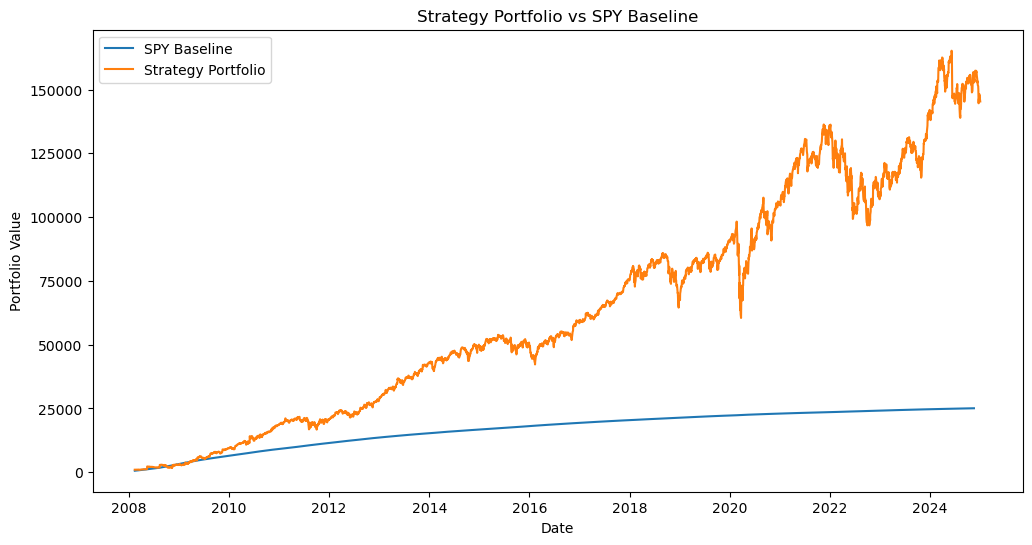

In [19]:
spy_baseline_value = spy_purchase_df.cumsum() * spy.iloc[-1]['Close'].values[0]

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(pd.to_datetime(spy_baseline_value.index), spy_baseline_value.values, label='SPY Baseline')
plt.plot(portfolio_value.index, portfolio_value.values, label='Strategy Portfolio')
plt.legend()
plt.title('Strategy Portfolio vs SPY Baseline')
plt.xlabel('Date')
plt.ylabel('Portfolio Value')
plt.show()

In [22]:
running_max = portfolio_value.cummax()
drawdown = (portfolio_value - running_max) / running_max
max_drawdown = drawdown.min()
print(f"Max drawdown: {max_drawdown:.2%}")

Max drawdown: -42.47%


In [23]:
# Calculate daily returns of the strategy portfolio
returns = portfolio_value.pct_change().dropna()

# Calculate Sharpe ratio (assume risk-free rate = 0)
sharpe_ratio = returns.mean() / returns.std() * (252 ** 0.5)
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")

Sharpe Ratio: 0.93


In [24]:
# Calculate CAGR (Compound Annual Growth Rate) for the strategy portfolio
start_value = portfolio_value.iloc[0]
end_value = portfolio_value.iloc[-1]
num_years = (portfolio_value.index[-1] - portfolio_value.index[0]).days / 365.25

cagr = (end_value / start_value) ** (1 / num_years) - 1
print(f"CAGR: {cagr:.2%}")

CAGR: 34.32%
